# Adversarial Attacks - Adversarial Patches Only

This tutorial was originally created by Phillip Lippe and modified by Dr. Brinnae Bent for use in "Emerging Trends in Explainable AI" at Duke University.

**This fork trains a physical-world adversarial sticker** initialized from `stickers/porsche_gt3rs_sticker.jpg` (Expectation over Transformation + content regularization so it still looks like the Porsche sticker).

Run on **Google Colab with a T4 GPU** (Runtime → Change runtime type → T4). Upload this repo folder (or at least `data/`, `saved_models/`, and `stickers/`) into the Colab working directory before training.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Kedar-V/adversarial-patches-sticker/blob/main/adversarial_attacks_patches.ipynb)


In [27]:
## Standard libraries
import os
import json
import math
import time
import numpy as np
import scipy.linalg

## Imports for plotting
import matplotlib.pyplot as plt
%matplotlib inline
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats('svg', 'pdf') # For export
from matplotlib.colors import to_rgb
import matplotlib
matplotlib.rcParams['lines.linewidth'] = 2.0
import seaborn as sns
sns.set()

## Progress bar
from tqdm.notebook import tqdm

## PyTorch
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.utils.data as data
import torch.optim as optim
# Torchvision
import torchvision
from torchvision.datasets import CIFAR10
from torchvision import transforms
# PyTorch Lightning
try:
    import pytorch_lightning as pl
except ModuleNotFoundError: # Google Colab does not have PyTorch Lightning installed by default. Hence, we do it here if necessary
    !pip install --quiet pytorch-lightning>=1.4
    import pytorch_lightning as pl
from pytorch_lightning.callbacks import LearningRateMonitor, ModelCheckpoint

# Path to the folder where the datasets are/should be downloaded (e.g. MNIST)
DATASET_PATH = "data"
# Path to the folder where the pretrained models are saved
CHECKPOINT_PATH = "saved_models/tutorial10"
# Natural-looking sticker used as the constrained adversarial patch
STICKER_PATH = "stickers/porsche_gt3rs_sticker.jpg"

# Setting the seed
pl.seed_everything(42)

# Ensure that all operations are deterministic on GPU (if used) for reproducibility
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Device: prefer CUDA (Colab T4), then Apple MPS, else CPU
if torch.cuda.is_available():
    device = torch.device("cuda:0")
    gpu_name = torch.cuda.get_device_name(0)
    print(f"Using device {device} ({gpu_name})")
    # T4 / Colab: keep workers modest to avoid DataLoader hangs
    NUM_WORKERS = 2
    torch.backends.cudnn.benchmark = True  # faster fixed-size convs on T4
elif getattr(torch.backends, "mps", None) is not None and torch.backends.mps.is_available():
    device = torch.device("mps")
    NUM_WORKERS = 0
    print("Using device", device)
else:
    device = torch.device("cpu")
    NUM_WORKERS = 0
    print("Using device", device, "(CPU — expect slow training)")


Seed set to 42


Using device mps


We have again a few download statements. This includes both a dataset, and a few pretrained patches we will use later.

In [28]:
import urllib.request
from urllib.error import HTTPError
import zipfile
# Github URL where the dataset is stored for this tutorial
base_url = "https://raw.githubusercontent.com/phlippe/saved_models/main/tutorial10/"
# Files to download
pretrained_files = [(DATASET_PATH, "TinyImageNet.zip"), (CHECKPOINT_PATH, "patches.zip")]
# Create checkpoint path if it doesn't exist yet
os.makedirs(DATASET_PATH, exist_ok=True)
os.makedirs(CHECKPOINT_PATH, exist_ok=True)

# For each file, download if missing; always unzip archives when the extracted folder is absent
for dir_name, file_name in pretrained_files:
    file_path = os.path.join(dir_name, file_name)
    if not os.path.isfile(file_path):
        file_url = base_url + file_name
        print(f"Downloading {file_url}...")
        try:
            urllib.request.urlretrieve(file_url, file_path)
        except HTTPError as e:
            print("Something went wrong. Please try to download the file from the GDrive folder, or contact the author with the full output including the following error:\n", e)
    if file_name.endswith(".zip") and os.path.isfile(file_path):
        # TinyImageNet.zip -> TinyImageNet/; patches.zip extracts .pt files into CHECKPOINT_PATH
        extract_marker = (
            os.path.join(dir_name, "TinyImageNet")
            if file_name == "TinyImageNet.zip"
            else os.path.join(dir_name, "toaster_32_patch.pt")
        )
        if not os.path.exists(extract_marker):
            print(f"Unzipping {file_path}...")
            with zipfile.ZipFile(file_path, "r") as zip_ref:
                zip_ref.extractall(dir_name)


## Setup

For our experiments in this notebook, we will use common CNN architectures trained on the ImageNet dataset. Such models are luckily provided by PyTorch's torchvision package, and hence we just need to load the model of our preference. For the results on the website and default on Google Colab, we use a ResNet34. Feel free to experiment with other architectures as well, the code is mainly independent of the specific architecture we choose.

In [29]:
# Load CNN architecture pretrained on ImageNet
os.environ["TORCH_HOME"] = CHECKPOINT_PATH
pretrained_model = torchvision.models.resnet34(weights='IMAGENET1K_V1')
pretrained_model = pretrained_model.to(device)

# No gradients needed for the network
pretrained_model.eval()
for p in pretrained_model.parameters():
    p.requires_grad = False


To perform adversarial attacks, we also need a dataset to work on. Given that the CNN model has been trained on ImageNet, it is only fair to perform the attacks on data from ImageNet. For this, we provide a small set of pre-processed images from the original ImageNet dataset (note that this dataset is shared under the same [license](http://image-net.org/download-faq) as the original ImageNet dataset). Specifically, we have 5 images for each of the 1000 labels of the dataset. We can load the data below, and create a corresponding data loader.

In [30]:
# Mean and Std from ImageNet
NORM_MEAN = np.array([0.485, 0.456, 0.406])
NORM_STD = np.array([0.229, 0.224, 0.225])
# No resizing and center crop necessary as images are already preprocessed.
plain_transforms = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=NORM_MEAN,
                         std=NORM_STD)
])

# Load dataset and create data loader
imagenet_path = os.path.join(DATASET_PATH, "TinyImageNet/")
assert os.path.isdir(imagenet_path), f"Could not find the ImageNet dataset at expected path \"{imagenet_path}\". " + \
                                     f"Please make sure to have downloaded the ImageNet dataset here, or change the {DATASET_PATH=} variable."
dataset = torchvision.datasets.ImageFolder(root=imagenet_path, transform=plain_transforms)
data_loader = data.DataLoader(
    dataset, batch_size=32, shuffle=False, drop_last=False, num_workers=NUM_WORKERS
)

# Load label names to interpret the label numbers 0 to 999
with open(os.path.join(imagenet_path, "label_list.json"), "r") as f:
    label_names = json.load(f)

def get_label_index(lab_str):
    assert lab_str in label_names, f"Label \"{lab_str}\" not found. Check the spelling of the class."
    return label_names.index(lab_str)


Before we start with our attacks, we should verify the performance of our model. As ImageNet has 1000 classes, simply looking at the accuracy is not sufficient to tell the performance of a model. Imagine a model that always predicts the true label as the second-highest class in its softmax output. Although we would say it recognizes the object in the image, it achieves an accuracy of 0. In ImageNet with 1000 classes, there is not always one clear label we can assign an image to. This is why for image classifications over so many classes, a common alternative metric is "Top-5 accuracy", which tells us how many times the true label has been within the 5 most-likely predictions of the model. As models usually perform quite well on those, we report the error (1 - accuracy) instead of the accuracy:

In [31]:
def eval_model(dataset_loader, img_func=None):
    tp, tp_5, counter = 0., 0., 0.
    for imgs, labels in tqdm(dataset_loader, desc="Validating..."):
        imgs = imgs.to(device)
        labels = labels.to(device)
        if img_func is not None:
            imgs = img_func(imgs, labels)
        with torch.no_grad():
            preds = pretrained_model(imgs)
        tp += (preds.argmax(dim=-1) == labels).sum()
        tp_5 += (preds.topk(5, dim=-1)[1] == labels[...,None]).any(dim=-1).sum()
        counter += preds.shape[0]
    acc = tp.float().item()/counter
    top5 = tp_5.float().item()/counter
    print(f"Top-1 error: {(100.0 * (1 - acc)):4.2f}%")
    print(f"Top-5 error: {(100.0 * (1 - top5)):4.2f}%")
    return acc, top5

In [32]:
_ = eval_model(data_loader)

Validating...:   0%|          | 0/157 [00:00<?, ?it/s]

Top-1 error: 19.38%
Top-5 error: 4.38%


The ResNet34 achives a decent error rate of 4.3% for the top-5 predictions. Next, we can look at some predictions of the model to get more familiar with the dataset. The function below plots an image along with a bar diagram of its predictions. We also prepare it to show adversarial examples for later applications.

In [33]:
def show_prediction(img, label, pred, K=5, adv_img=None, noise=None):

    if isinstance(img, torch.Tensor):
        # Tensor image to numpy
        img = img.cpu().permute(1, 2, 0).numpy()
        img = (img * NORM_STD[None,None]) + NORM_MEAN[None,None]
        img = np.clip(img, a_min=0.0, a_max=1.0)
        label = label.item()

    # Plot on the left the image with the true label as title.
    # On the right, have a horizontal bar plot with the top k predictions including probabilities
    if noise is None or adv_img is None:
        fig, ax = plt.subplots(1, 2, figsize=(10,2), gridspec_kw={'width_ratios': [1, 1]})
    else:
        fig, ax = plt.subplots(1, 5, figsize=(12,2), gridspec_kw={'width_ratios': [1, 1, 1, 1, 2]})

    ax[0].imshow(img)
    ax[0].set_title(label_names[label])
    ax[0].axis('off')

    if adv_img is not None and noise is not None:
        # Visualize adversarial images
        adv_img = adv_img.cpu().permute(1, 2, 0).numpy()
        adv_img = (adv_img * NORM_STD[None,None]) + NORM_MEAN[None,None]
        adv_img = np.clip(adv_img, a_min=0.0, a_max=1.0)
        ax[1].imshow(adv_img)
        ax[1].set_title('Adversarial')
        ax[1].axis('off')
        # Visualize noise
        noise = noise.cpu().permute(1, 2, 0).numpy()
        noise = noise * 0.5 + 0.5 # Scale between 0 to 1
        ax[2].imshow(noise)
        ax[2].set_title('Noise')
        ax[2].axis('off')
        # buffer
        ax[3].axis('off')

    if abs(pred.sum().item() - 1.0) > 1e-4:
        pred = torch.softmax(pred, dim=-1)
    topk_vals, topk_idx = pred.topk(K, dim=-1)
    topk_vals, topk_idx = topk_vals.cpu().numpy(), topk_idx.cpu().numpy()
    ax[-1].barh(np.arange(K), topk_vals*100.0, align='center', color=["C0" if topk_idx[i]!=label else "C2" for i in range(K)])
    ax[-1].set_yticks(np.arange(K))
    ax[-1].set_yticklabels([label_names[c] for c in topk_idx])
    ax[-1].invert_yaxis()
    ax[-1].set_xlabel('Confidence')
    ax[-1].set_title('Predictions')

    plt.show()
    plt.close()

Let's visualize a few images below:

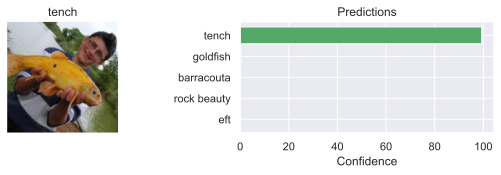

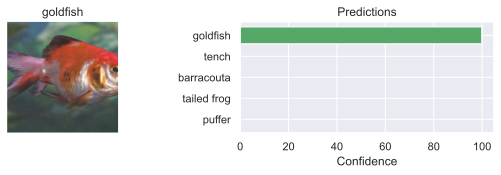

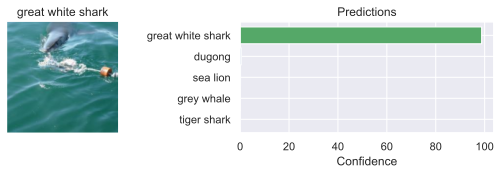

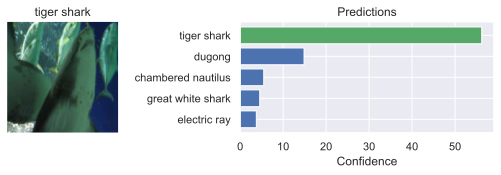

In [34]:
exmp_batch, label_batch = next(iter(data_loader))
with torch.no_grad():
    preds = pretrained_model(exmp_batch.to(device))
for i in range(1,17,5):
    show_prediction(exmp_batch[i], label_batch[i], preds[i])

The bar plot on the right shows the top-5 predictions of the model with their class probabilities. We denote the class probabilities with "confidence" as it somewhat resembles how confident the network is that the image is of one specific class. Some of the images have a highly peaked probability distribution, and we would expect the model to be rather robust against noise for those. However, we will see below that this is not always the case. Note that all of the images are of fish because the data loader doesn't shuffle the dataset. Otherwise, we would get different images every time we run the notebook, which would make it hard to discuss the results on the static version.

### Adversarial Patches

Instead of changing every pixel by a little bit, we can also try to change a small part of the image into whatever values we would like. In other words, we will create a small image patch that covers a minor part of the original image but causes the model to confidentially predict a specific class we choose. This form of attack is an even bigger threat in real-world applications than FSGM. Imagine a network in an autonomous car that receives a live image from a camera. Another driver could print out a specific pattern and put it on the back of his/her vehicle to make the autonomous car believe that the car is actually a pedestrian. Meanwhile, humans would not notice it. [Tom Brown et al.](https://arxiv.org/pdf/1712.09665.pdf) proposed a way of learning such adversarial image patches robustly in 2017 and provided a short demonstration on [YouTube](https://youtu.be/i1sp4X57TL4). Interestingly, if you add a small picture of the target class (here *toaster*) to the original image, the model does not pick it up at all. A specifically designed patch, however, which only roughly looks like a toaster, can change the network's prediction instantaneously.

[![Adversarial patch in real world](https://img.youtube.com/vi/i1sp4X57TL4/0.jpg)](https://youtu.be/i1sp4X57TL4)

Let's take a closer look at how we can actually train such patches. We calculate gradients for the input, and update our adversarial input correspondingly. We do not calculate a gradient for every pixel. Instead, we replace parts of the input image with our patch and then calculate the gradients just for our patch. Secondly, we don't just do it for one image, but we want the patch to work with any possible image. Hence, we have a whole training loop where we train the patch using SGD. Lastly, image patches are usually designed to make the model predict a specific class, not just any other arbitrary class except the true label. For instance, we can try to create a patch for the class "toaster" and train the patch so that our pretrained model predicts the class "toaster" for any image with the patch in it.

[Brown et al.](https://arxiv.org/pdf/1712.09665.pdf) randomly rotated and scaled the patch during training before placing it at a random position in an input image. This makes the patch more robust to small changes and is necessary if we want to fool a neural network in a real-world application. 

This tutorial only shows how to make the patch robust to the location in the image.

Here is where you could:
* Randomly rotate patch
* Randomly scale the patch
* Improve random location of patch in the image

In [35]:
def place_patch(img, patch):
    for i in range(img.shape[0]):
        h_offset = np.random.randint(0,img.shape[2]-patch.shape[1]-1)
        w_offset = np.random.randint(0,img.shape[3]-patch.shape[2]-1)
        img[i,:,h_offset:h_offset+patch.shape[1],w_offset:w_offset+patch.shape[2]] = patch_forward(patch)
    return img

The patch itself will be an `nn.Parameter` whose values are in the range between $-\infty$ and $\infty$. Images are, however, naturally limited in their range, and thus we write a small function that maps the parameter into the image value range of ImageNet:

In [36]:
TENSOR_MEANS, TENSOR_STD = torch.FloatTensor(NORM_MEAN)[:,None,None], torch.FloatTensor(NORM_STD)[:,None,None]
def patch_forward(patch):
    # Map patch values from [-infty,infty] to ImageNet min and max
    patch = (torch.tanh(patch) + 1 - 2 * TENSOR_MEANS) / (2 * TENSOR_STD)
    return patch

Before looking at the actual training code, we can write a small evaluation function. We evaluate the success of a patch by how many times we were able to fool the network into predicting our target class. A simple function for this is implemented below.

In [37]:
def eval_patch(model, patch, val_loader, target_class):
    model.eval()
    tp, tp_5, counter = 0., 0., 0.
    with torch.no_grad():
        for img, img_labels in tqdm(val_loader, desc="Validating...", leave=False):
            # For stability, place the patch at 4 random locations per image, and average the performance
            for _ in range(4):
                patch_img = place_patch(img, patch)
                patch_img = patch_img.to(device)
                img_labels = img_labels.to(device)
                pred = model(patch_img)
                # In the accuracy calculation, we need to exclude the images that are of our target class
                # as we would not "fool" the model into predicting those
                tp += torch.logical_and(pred.argmax(dim=-1) == target_class, img_labels != target_class).sum()
                tp_5 += torch.logical_and((pred.topk(5, dim=-1)[1] == target_class).any(dim=-1), img_labels != target_class).sum()
                counter += (img_labels != target_class).sum()
    acc = tp/counter
    top5 = tp_5/counter
    return acc, top5

Finally, we can look at the training loop. Given a model to fool, a target class to design the patch for, and a size $k$ of the patch in the number of pixels, we first start by creating a parameter of size $3\times k\times k$. These are the only parameters we will train, and the network itself remains untouched. We use a simple SGD optimizer with momentum to minimize the classification loss of the model given the patch in the image. While we first start with a very high loss due to the good initial performance of the network, the loss quickly decreases once we start changing the patch. In the end, the patch will represent patterns that are characteristic of the class. For instance, if we would want the model to predict a "goldfish" in every image, we would expect the pattern to look somewhat like a goldfish. Over the iterations, the model finetunes the pattern and, hopefully, achieves a high fooling accuracy.

In [38]:
def patch_attack(model, target_class, patch_size=64, num_epochs=5):
    # Leave a small set of images out to check generalization
    # In most of our experiments, the performance on the hold-out data points
    # was as good as on the training set. Overfitting was little possible due
    # to the small size of the patches.
    train_set, val_set = torch.utils.data.random_split(dataset, [4500, 500])
    train_loader = data.DataLoader(
        train_set, batch_size=32, shuffle=True, drop_last=True, num_workers=NUM_WORKERS
    )
    val_loader = data.DataLoader(
        val_set, batch_size=32, shuffle=False, drop_last=False, num_workers=NUM_WORKERS
    )

    # Create parameter and optimizer
    if not isinstance(patch_size, tuple):
        patch_size = (patch_size, patch_size)
    patch = nn.Parameter(torch.zeros(3, patch_size[0], patch_size[1]), requires_grad=True)
    optimizer = torch.optim.SGD([patch], lr=1e-1, momentum=0.8)
    loss_module = nn.CrossEntropyLoss()

    # Training loop
    for epoch in range(num_epochs):
        t = tqdm(train_loader, leave=False)
        for img, _ in t:
            img = place_patch(img, patch)
            img = img.to(device)
            pred = model(img)
            labels = torch.zeros(img.shape[0], device=pred.device, dtype=torch.long).fill_(target_class)
            loss = loss_module(pred, labels)
            optimizer.zero_grad()
            loss.mean().backward()
            optimizer.step()
            t.set_description(f"Epoch {epoch}, Loss: {loss.item():4.2f}")

    # Final validation
    acc, top5 = eval_patch(model, patch, val_loader, target_class)

    return patch.data, {"acc": acc.item(), "top5": top5.item()}

## Train for the physical world (EOT) — Porsche sticker patch

Digital patches often fail after **printing + camera capture** (color shift, blur, glare, distance, angle).

Here we turn `stickers/porsche_gt3rs_sticker.jpg` into a **constrained adversarial sticker**:
- initialize the patch from the Porsche artwork (not random noise)
- paste with a **circular mask** (die-cut sticker shape)
- train with **Expectation over Transformation (EOT)**: scale, rotation, **horizontal/vertical flips**, brightness/contrast, blur, noise
- **content loss is weak by default** — we prioritize fooling the 5 target classes over looking identical to the source art
- light **total-variation** penalty for printability

Defaults below are tuned for a **Colab T4** (batch 8, **patch 1024px**, ~10 epochs) and train one sticker per **original tutorial class**: toaster, goldfish, school bus, lipstick, pineapple. The high-res patch is downscaled onto 224px training images using a random *image coverage* fraction so placement still looks realistic.


In [ ]:
# Physical-world Porsche sticker patch (EOT + content constraint)
# Tuned for Google Colab T4 GPU
from PIL import Image
import torchvision.transforms.functional as TF

def _rand_float(lo, hi):
    return lo + (hi - lo) * float(torch.rand(()).item())

def ensure_sticker(path=STICKER_PATH):
    """Return sticker path; on Colab, prompt for upload if missing."""
    if os.path.isfile(path):
        return path
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    try:
        from google.colab import files  # type: ignore
        print(f"Missing {path}. Upload porsche_gt3rs_sticker.jpg from the stickers/ folder...")
        uploaded = files.upload()
        name = next(iter(uploaded))
        with open(path, "wb") as f:
            f.write(uploaded[name])
        return path
    except ImportError as e:
        raise FileNotFoundError(
            f"Sticker not found at {path}. Place porsche_gt3rs_sticker.jpg under stickers/."
        ) from e

def load_circular_sticker(path=STICKER_PATH, size=1024):
    """Center-crop the circular Porsche sticker, resize, and build a soft circular alpha mask."""
    img = Image.open(ensure_sticker(path)).convert("RGB")
    w, h = img.size
    side = min(w, h)
    left, top = (w - side) // 2, (h - side) // 2
    img = img.crop((left, top, left + side, top + side)).resize((size, size), Image.BICUBIC)
    rgb = torch.from_numpy(np.asarray(img).astype(np.float32) / 255.0).permute(2, 0, 1)  # 3xHxW in [0,1]

    yy, xx = torch.meshgrid(
        torch.linspace(-1, 1, size), torch.linspace(-1, 1, size), indexing="ij"
    )
    # Soft edge so rotation/resize antialiasing looks natural
    r = torch.sqrt(xx ** 2 + yy ** 2)
    mask = (1.0 - ((r - 0.92) / 0.08).clamp(0, 1)).clamp(0, 1)  # HxW
    return rgb, mask

def rgb_to_patch_param(rgb):
    """Map RGB [0,1] into the unbounded parameter space used by patch_forward / tanh."""
    return torch.atanh(rgb.clamp(1e-4, 1.0 - 1e-4) * 2 - 1)

def patch_param_to_rgb(patch):
    return (torch.tanh(patch) + 1) / 2

def patch_forward_device(patch):
    """Same as patch_forward, but safe when patch lives on GPU."""
    means = TENSOR_MEANS.to(patch.device)
    stds = TENSOR_STD.to(patch.device)
    return (torch.tanh(patch) + 1 - 2 * means) / (2 * stds)

def apply_physical_transforms_to_patch(
    patch_img, mask, max_rotate_deg=45.0, hflip_prob=0.5, vflip_prob=0.3
):
    """Augment CxHxW normalized patch + HxW mask together (print/camera EOT).

    Includes flips + wider rotation so a printed sticker still works when
    held upside-down, mirrored in a selfie cam, or stuck at an odd angle.
    """
    brightness = _rand_float(0.7, 1.3)
    contrast = _rand_float(0.7, 1.3)
    std = TENSOR_STD.to(patch_img.device)
    patch_img = patch_img * contrast + (brightness - 1.0) / std
    patch_img = patch_img + 0.05 * torch.randn_like(patch_img)

    # Random flips (sticker orientation / mirrored camera)
    if torch.rand(1).item() < hflip_prob:
        patch_img = TF.hflip(patch_img)
        mask = TF.hflip(mask.unsqueeze(0)).squeeze(0)
    if torch.rand(1).item() < vflip_prob:
        patch_img = TF.vflip(patch_img)
        mask = TF.vflip(mask.unsqueeze(0)).squeeze(0)

    # Continuous rotation (sticker not perfectly aligned on the object)
    angle = _rand_float(-max_rotate_deg, max_rotate_deg)
    patch_img = TF.rotate(
        patch_img, angle=angle, interpolation=TF.InterpolationMode.BILINEAR, fill=0.0
    )
    mask = TF.rotate(
        mask.unsqueeze(0), angle=angle, interpolation=TF.InterpolationMode.BILINEAR, fill=0.0
    ).squeeze(0)

    if torch.rand(1).item() < 0.7:
        k = 3
        weight = torch.ones(3, 1, k, k, device=patch_img.device) / (k * k)
        patch_img = F.conv2d(patch_img.unsqueeze(0), weight, padding=k // 2, groups=3).squeeze(0)
        mweight = torch.ones(1, 1, k, k, device=mask.device) / (k * k)
        mask = F.conv2d(mask.unsqueeze(0).unsqueeze(0), mweight, padding=k // 2).squeeze(0).squeeze(0)

    return patch_img, mask.clamp(0, 1)

def apply_camera_transforms_to_image(img):
    """BxCxHxW ImageNet-normalized batch: lighting / sensor noise after pasting."""
    b = _rand_float(0.85, 1.15)
    c = _rand_float(0.85, 1.15)
    img = img * c + (b - 1.0) / TENSOR_STD.to(img.device).clamp_min(1e-6)
    img = img + 0.02 * torch.randn_like(img)
    if torch.rand(1).item() < 0.5:
        k = 3
        weight = torch.ones(3, 1, k, k, device=img.device) / (k * k)
        img = F.conv2d(img, weight, padding=k // 2, groups=3)
    return img

def place_patch_physical(img, patch, mask=None, scale_range=(0.3, 0.75), max_rotate_deg=45.0):
    """Paste a randomly scaled/rotated/flipped sticker with circular alpha blending.

    scale_range is the fraction of the *host image's shorter side* the sticker should
    cover (not a multiplier on patch resolution). That keeps 1024px print patches
    from always filling a 224px training image.
    """
    img = img.clone()
    base = patch_forward_device(patch)  # 3xHxW, ImageNet-normalized
    if mask is None:
        mask = torch.ones(base.shape[1], base.shape[2], device=base.device)
    else:
        mask = mask.to(device=base.device, dtype=base.dtype)

    for i in range(img.shape[0]):
        frac = _rand_float(*scale_range)
        short = min(img.shape[2], img.shape[3])
        ph0, pw0 = base.shape[1], base.shape[2]
        if ph0 >= pw0:
            new_h = max(8, min(int(short * frac), img.shape[2] - 1))
            new_w = max(8, min(int(round(new_h * pw0 / ph0)), img.shape[3] - 1))
        else:
            new_w = max(8, min(int(short * frac), img.shape[3] - 1))
            new_h = max(8, min(int(round(new_w * ph0 / pw0)), img.shape[2] - 1))

        patch_i = TF.resize(base, [new_h, new_w], antialias=True)
        mask_i = TF.resize(mask.unsqueeze(0), [new_h, new_w], antialias=True).squeeze(0)
        patch_i, mask_i = apply_physical_transforms_to_patch(
            patch_i, mask_i, max_rotate_deg=max_rotate_deg
        )

        ph, pw = patch_i.shape[1], patch_i.shape[2]
        if ph >= img.shape[2] or pw >= img.shape[3]:
            ph = min(ph, img.shape[2] - 1)
            pw = min(pw, img.shape[3] - 1)
            patch_i = TF.resize(patch_i, [ph, pw], antialias=True)
            mask_i = TF.resize(mask_i.unsqueeze(0), [ph, pw], antialias=True).squeeze(0)

        h_offset = np.random.randint(0, img.shape[2] - patch_i.shape[1])
        w_offset = np.random.randint(0, img.shape[3] - patch_i.shape[2])
        region = img[i, :, h_offset:h_offset + patch_i.shape[1], w_offset:w_offset + patch_i.shape[2]]
        m = mask_i.unsqueeze(0)
        img[i, :, h_offset:h_offset + patch_i.shape[1], w_offset:w_offset + patch_i.shape[2]] = (
            m * patch_i + (1.0 - m) * region
        )

    return apply_camera_transforms_to_image(img)

def total_variation(patch_img):
    """Encourage smooth, printable patterns."""
    tv_h = torch.mean(torch.abs(patch_img[:, 1:, :] - patch_img[:, :-1, :]))
    tv_w = torch.mean(torch.abs(patch_img[:, :, 1:] - patch_img[:, :, :-1]))
    return tv_h + tv_w

def sticker_patch_attack(
    model,
    target_class,
    sticker_path=STICKER_PATH,
    patch_size=1024,
    num_epochs=10,
    eot_samples=2,
    tv_weight=0.005,
    content_weight=0.01,
    scale_range=(0.3, 0.75),
    lr=5e-2,
    batch_size=8,
    num_workers=None,
):
    """
    Train a constrained adversarial sticker initialized from the Porsche artwork.
    content_weight: soft look regularizer only — keep low so fooling the target class wins.
    Defaults prioritize attack success over looking identical to the source sticker.
    scale_range: fraction of the host image's shorter side covered by the sticker.
    """
    if num_workers is None:
        num_workers = NUM_WORKERS

    train_set, val_set = torch.utils.data.random_split(dataset, [4500, 500])
    train_loader = data.DataLoader(
        train_set, batch_size=batch_size, shuffle=True, drop_last=True, num_workers=num_workers
    )
    val_loader = data.DataLoader(
        val_set, batch_size=batch_size, shuffle=False, drop_last=False, num_workers=num_workers
    )

    sticker_rgb, sticker_mask = load_circular_sticker(sticker_path, size=patch_size)
    sticker_rgb = sticker_rgb.to(device)
    sticker_mask = sticker_mask.to(device)

    # Initialize patch parameters from the real sticker (not noise)
    patch = nn.Parameter(rgb_to_patch_param(sticker_rgb).detach().clone(), requires_grad=True)
    optimizer = torch.optim.SGD([patch], lr=lr, momentum=0.8)
    loss_module = nn.CrossEntropyLoss()

    model.eval()
    for p in model.parameters():
        p.requires_grad_(False)

    for epoch in range(num_epochs):
        t = tqdm(train_loader, leave=False)
        for img, _ in t:
            img = img.to(device)
            labels = torch.full((img.shape[0],), target_class, device=device, dtype=torch.long)

            loss = 0.0
            for _ in range(eot_samples):
                patched = place_patch_physical(
                    img, patch, mask=sticker_mask, scale_range=scale_range
                )
                pred = model(patched)
                loss = loss + loss_module(pred, labels)
            loss = loss / eot_samples

            rgb = patch_param_to_rgb(patch)
            # Content loss only inside the circular sticker
            content = F.mse_loss(rgb * sticker_mask, sticker_rgb * sticker_mask)
            loss = loss + content_weight * content + tv_weight * total_variation(rgb)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            t.set_description(
                f"Sticker epoch {epoch}, Loss: {loss.item():4.2f}, content: {content.item():.4f}"
            )

    tp, tp_5, counter = 0.0, 0.0, 0.0
    with torch.no_grad():
        for imgs, img_labels in tqdm(val_loader, desc="Sticker validating...", leave=False):
            for _ in range(4):
                patch_img = place_patch_physical(
                    imgs.to(device), patch, mask=sticker_mask, scale_range=scale_range
                )
                img_labels_d = img_labels.to(device)
                pred = model(patch_img)
                tp += torch.logical_and(pred.argmax(dim=-1) == target_class, img_labels_d != target_class).sum()
                tp_5 += torch.logical_and(
                    (pred.topk(5, dim=-1)[1] == target_class).any(dim=-1), img_labels_d != target_class
                ).sum()
                counter += (img_labels_d != target_class).sum()
    acc, top5 = (tp / counter).item(), (tp_5 / counter).item()
    print(f"Sticker-val fool rate: top1={acc:.3f}, top5={top5:.3f}")
    return patch.detach().cpu(), sticker_mask.detach().cpu(), {"acc": acc, "top5": top5}

# Keep a thin alias for older cell names
def physical_patch_attack(*args, **kwargs):
    patch, _mask, metrics = sticker_patch_attack(*args, **kwargs)
    return patch, metrics

print("Porsche sticker EOT trainers ready: load_circular_sticker, sticker_patch_attack")
print(f"Sticker path: {STICKER_PATH} (exists={os.path.isfile(STICKER_PATH)})")


In [ ]:
# Demo: train the sticker as a physical adversarial patch for the original tutorial classes
# Same targets as the digital multi-class sweep below.
PHYS_CLASSES = ["toaster", "goldfish", "school bus", "lipstick", "pineapple"]
PHYS_SIZE = 1024            # high-res printable sticker
PHYS_EPOCHS = 15            # more epochs => stronger fool rates on the 5 classes
# Attack-first: keep these small so CE fooling loss dominates sticker appearance
CONTENT_WEIGHT = 0.01       # was 0.08; raise only if the patch stops looking usable
TV_WEIGHT = 0.005           # light printability; don't over-smooth the attack
BATCH_SIZE = 8              # T4 + 1024px; drop to 4 if you OOM
SCALE_RANGE = (0.3, 0.75)   # on-image coverage fraction

# Preview the source sticker + circular crop used as initialization
_src_rgb, _src_mask = load_circular_sticker(STICKER_PATH, size=PHYS_SIZE)
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
axes[0].imshow(Image.open(ensure_sticker(STICKER_PATH)))
axes[0].set_title("Source file")
axes[0].axis("off")
axes[1].imshow(_src_rgb.permute(1, 2, 0).numpy())
axes[1].set_title(f"Crop {PHYS_SIZE}px")
axes[1].axis("off")
axes[2].imshow((_src_rgb * _src_mask).permute(1, 2, 0).numpy())
axes[2].set_title("Circular mask")
axes[2].axis("off")
plt.tight_layout()
plt.show()

export_dir = os.path.join(CHECKPOINT_PATH, "physical_exports")
os.makedirs(export_dir, exist_ok=True)
phys_results = {}

exmp_batch, label_batch = next(iter(data_loader))

for PHYS_CLASS in PHYS_CLASSES:
    print("=" * 60)
    print(f"Training sticker → {PHYS_CLASS}")
    target_idx = label_names.index(PHYS_CLASS)
    phys_patch, phys_mask, phys_metrics = sticker_patch_attack(
        pretrained_model,
        target_class=target_idx,
        sticker_path=STICKER_PATH,
        patch_size=PHYS_SIZE,
        num_epochs=PHYS_EPOCHS,
        eot_samples=2,
        tv_weight=TV_WEIGHT,
        content_weight=CONTENT_WEIGHT,
        scale_range=SCALE_RANGE,
        lr=5e-2,
        batch_size=BATCH_SIZE,
    )
    print(PHYS_CLASS, PHYS_SIZE, phys_metrics)
    phys_results[PHYS_CLASS] = {"metrics": phys_metrics, "patch": phys_patch, "mask": phys_mask}

    phys_rgb = patch_param_to_rgb(phys_patch)
    fig, axes = plt.subplots(1, 2, figsize=(6, 3))
    axes[0].imshow(_src_rgb.permute(1, 2, 0).numpy())
    axes[0].set_title("Original sticker")
    axes[0].axis("off")
    axes[1].imshow(phys_rgb.clamp(0, 1).permute(1, 2, 0).cpu().numpy())
    axes[1].set_title(f"Adversarial → {PHYS_CLASS}")
    axes[1].axis("off")
    plt.tight_layout()
    plt.show()

    safe_name = PHYS_CLASS.replace(" ", "_")
    pt_path = os.path.join(export_dir, f"sticker_{safe_name}_{PHYS_SIZE}_physical.pt")
    png_path = os.path.join(export_dir, f"sticker_{safe_name}_{PHYS_SIZE}_physical.png")
    print_rgb = phys_rgb.clamp(0, 1) * phys_mask + (1.0 - phys_mask)
    print_np = print_rgb.permute(1, 2, 0).cpu().numpy()
    torch.save(
        {"patch": phys_patch, "mask": phys_mask, "class": PHYS_CLASS, "size": PHYS_SIZE, "metrics": phys_metrics},
        pt_path,
    )
    plt.imsave(png_path, print_np)
    print("Saved:", pt_path)
    print("Print:", png_path)

    with torch.no_grad():
        preview = place_patch_physical(
            exmp_batch.to(device), phys_patch.to(device), mask=phys_mask.to(device)
        )
        preds = pretrained_model(preview)
    for i in range(1, 12, 5):
        show_prediction(preview[i].cpu(), label_batch[i], preds[i].cpu())

print("Done. Fool rates by class:")
for cname, payload in phys_results.items():
    print(f"  {cname}: {payload['metrics']}")


The cells above train the **Porsche sticker** patch. The section below is the original digital multi-class sweep (pretrained noise-initialized patches). You can skip it if you only care about the printable sticker.

To get some experience with what to expect from an adversarial patch attack, we want to train multiple patches for different classes. As the training of a patch can take one or two minutes on a GPU, we have provided a couple of pre-trained patches including their results on the full dataset. The results are saved in a JSON file, which is loaded below.

In [ ]:
# Load evaluation results of the pretrained patches
json_results_file = os.path.join(CHECKPOINT_PATH, "patch_results.json")
json_results = {}
if os.path.isfile(json_results_file):
    with open(json_results_file, "r") as f:
        json_results = json.load(f)

# If you train new patches, you can save the results via calling this function
def save_results(patch_dict):
    result_dict = {cname: {psize: [t.item() if isinstance(t, torch.Tensor) else t
                                   for t in patch_dict[cname][psize]["results"]]
                           for psize in patch_dict[cname]}
                   for cname in patch_dict}
    with open(os.path.join(CHECKPOINT_PATH, "patch_results.json"), "w") as f:
        json.dump(result_dict, f, indent=4)


Additionally, we implement a function to train and evaluate patches for a list of classes and patch sizes. The pretrained patches include the classes *toaster*, *goldfish*, *school bus*, *lipstick*, and *pineapple*. We chose the classes arbitrarily to cover multiple domains (animals, vehicles, fruits, devices, etc.). We trained each class for three different patch sizes: $32\times32$ pixels, $48\times48$ pixels, and $64\times64$ pixels. We can load them in the two cells below.

In [ ]:
def get_patches(class_names, patch_sizes):
    result_dict = dict()

    # Loop over all classes and patch sizes
    for name in class_names:
        result_dict[name] = dict()
        for patch_size in patch_sizes:
            c = label_names.index(name)
            file_name = os.path.join(CHECKPOINT_PATH, f"{name}_{patch_size}_patch.pt")
            # Load patch if pretrained file exists, otherwise start training
            if not os.path.isfile(file_name):
                patch, val_results = patch_attack(pretrained_model, target_class=c, patch_size=patch_size, num_epochs=5)
                print(f"Validation results for {name} and {patch_size}:", val_results)
                torch.save(patch, file_name)
            else:
                patch = torch.load(file_name)
            # Load evaluation results if exist, otherwise manually evaluate the patch
            if name in json_results:
                results = json_results[name][str(patch_size)]
            else:
                results = eval_patch(pretrained_model, patch, data_loader, target_class=c)

            # Store results and the patches in a dict for better access
            result_dict[name][patch_size] = {
                "results": results,
                "patch": patch
            }

    return result_dict


Feel free to add any additional classes and/or patch sizes.

In [ ]:
class_names = ['toaster', 'goldfish', 'school bus', 'lipstick', 'pineapple']
patch_sizes = [32, 48, 64]

patch_dict = get_patches(class_names, patch_sizes)
# save_results(patch_dict) # Uncomment if you add new class names and want to save the new results

Before looking at the quantitative results, we can actually visualize the patches.

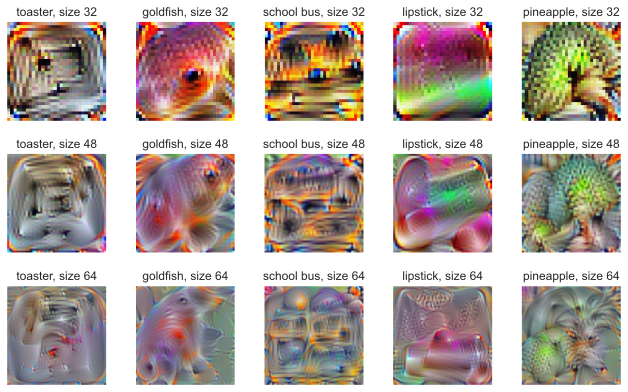

In [ ]:
def show_patches():
    fig, ax = plt.subplots(len(patch_sizes), len(class_names), figsize=(len(class_names)*2.2, len(patch_sizes)*2.2))
    for c_idx, cname in enumerate(class_names):
        for p_idx, psize in enumerate(patch_sizes):
            patch = patch_dict[cname][psize]["patch"]
            patch = (torch.tanh(patch) + 1) / 2 # Parameter to pixel values
            patch = patch.cpu().permute(1, 2, 0).numpy()
            patch = np.clip(patch, a_min=0.0, a_max=1.0)
            ax[p_idx][c_idx].imshow(patch)
            ax[p_idx][c_idx].set_title(f"{cname}, size {psize}")
            ax[p_idx][c_idx].axis('off')
    fig.subplots_adjust(hspace=0.3, wspace=0.3)
    plt.show()
show_patches()

We can see a clear difference between patches of different classes and sizes. In the smallest size, $32\times 32$ pixels, some of the patches clearly resemble their class. For instance, the goldfish patch clearly shows a goldfish. The eye and the color are very characteristic of the class. Overall, the patches with $32$ pixels have very strong colors that are typical for their class (yellow school bus, pink lipstick, greenish pineapple). The larger the patch becomes, the more stretched the pattern becomes. For the goldfish, we can still spot regions that might represent eyes and the characteristic orange color, but it is not clearly a single fish anymore. For the pineapple, we might interpret the top part of the image as the leaves of pineapple fruit, but it is more abstract than our small patches. Nevertheless, we can easily spot the alignment of the patch to class, even on the largest scale.

Let's now look at the quantitative results.

In [ ]:
%%html
<!-- Some HTML code to increase font size in the following table -->
<style>
th {font-size: 120%;}
td {font-size: 120%;}
</style>

In [ ]:
import tabulate
from IPython.display import display, HTML

def show_table(top_1=True):
    i = 0 if top_1 else 1
    table = [[name] + [f"{(100.0 * patch_dict[name][psize]['results'][i]):4.2f}%" for psize in patch_sizes]
             for name in class_names]
    display(HTML(tabulate.tabulate(table, tablefmt='html', headers=["Class name"] + [f"Patch size {psize}x{psize}" for psize in patch_sizes])))

First, we will create a table of top-1 accuracy, meaning that how many images have been classified with the target class as highest prediction?

In [ ]:
show_table(top_1=True)

Class name,Patch size 32x32,Patch size 48x48,Patch size 64x64
toaster,48.89%,90.48%,98.58%
goldfish,69.53%,93.53%,98.34%
school bus,78.79%,93.95%,98.22%
lipstick,43.36%,86.05%,96.41%
pineapple,79.74%,94.48%,98.72%


The clear trend, that we would also have expected, is that the larger the patch, the easier it is to fool the model. For the largest patch size of $64\times 64$, we are able to fool the model on almost all images, despite the patch covering only 8% of the image. The smallest patch actually covers 2% of the image, which is almost neglectable. Still, the fooling accuracy is quite remarkable. A large variation can be however seen across classes. While *school bus* and *pineapple* seem to be classes that were easily predicted, *toaster* and *lipstick* seem to be much harder for creating a patch. It is hard to intuitively explain why our patches underperform on those classes. Nonetheless, a fooling accuracy of >40% is still very good for such a tiny patch.

Let's also take a look at the top-5 accuracy:

In [ ]:
show_table(top_1=False)

Class name,Patch size 32x32,Patch size 48x48,Patch size 64x64
toaster,72.02%,98.12%,99.93%
goldfish,86.31%,99.07%,99.95%
school bus,91.64%,99.15%,99.89%
lipstick,70.10%,96.86%,99.73%
pineapple,92.23%,99.26%,99.96%


We see a very similar pattern across classes and patch sizes. The patch size $64$ obtains >99.7% top-5 accuracy for any class, showing that we can almost fool the network on any image. A top-5 accuracy of >70% for the hard classes and small patches is still impressive and shows how vulnerable deep CNNs are to such attacks.

Finally, let's create some example visualizations of the patch attack in action.

In [ ]:
def perform_patch_attack(patch):
    patch_batch = exmp_batch.clone()
    patch_batch = place_patch(patch_batch, patch)
    with torch.no_grad():
        patch_preds = pretrained_model(patch_batch.to(device))
    for i in range(1,17,5):
        show_prediction(patch_batch[i], label_batch[i], patch_preds[i])

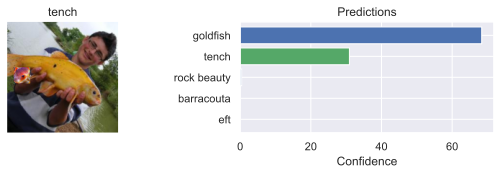

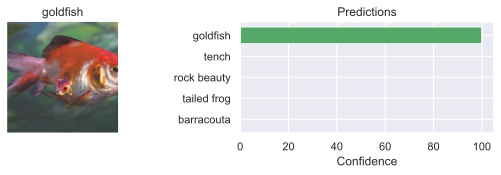

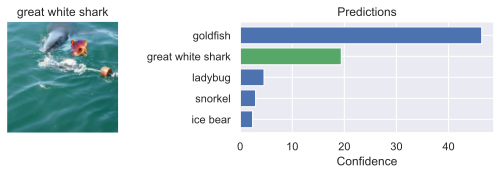

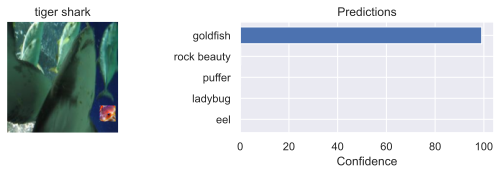

In [ ]:
perform_patch_attack(patch_dict['goldfish'][32]['patch'])

The tiny goldfish patch can change all of the predictions to "goldfish" as top class. Note that the patch attacks work especially well if the input image is semantically similar to the target class (e.g. a fish and the target class "goldfish" works better than an airplane image with that patch). Nevertheless, we can also let the network predict semantically dis-similar classes by using a larger patch:

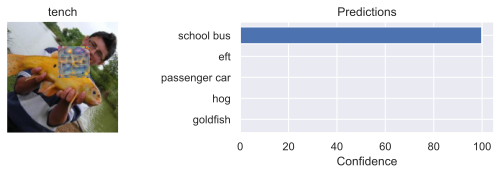

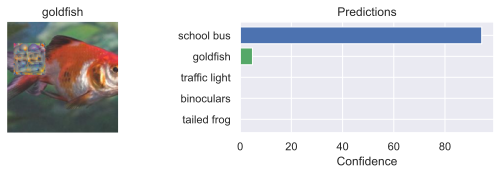

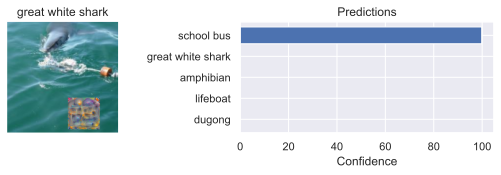

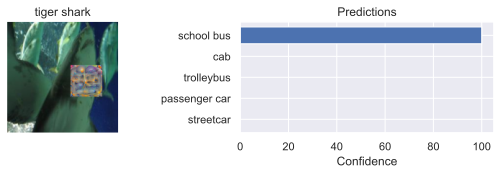

In [ ]:
perform_patch_attack(patch_dict['school bus'][64]['patch'])

Although none of the images have anything to do with an American school bus, the high confidence of often 100% shows how powerful such attacks can be. With a few lines of code and access to the model, we were able to generate patches that we add to any image to make the model predict any class we want.

## References

This tutorial was originally created by Phillip Lippe. 
[![View notebooks on Github](https://img.shields.io/static/v1.svg?logo=github&label=Repo&message=View%20On%20Github&color=lightgrey)](https://github.com/phlippe/uvadlc_notebooks/blob/master/docs/tutorial_notebooks/tutorial10/Adversarial_Attacks.ipynb)
[![Open In Collab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phlippe/uvadlc_notebooks/blob/master/docs/tutorial_notebooks/tutorial10/Adversarial_Attacks.ipynb)  

[1] Goodfellow, Ian J., Jonathon Shlens, and Christian Szegedy. "Explaining and harnessing adversarial examples." ICLR 2015.

[2] Hendrik Metzen, Jan, et al. "Universal adversarial perturbations against semantic image segmentation." Proceedings of the IEEE International Conference on Computer Vision. 2017.

[3] Anant Jain. "Breaking neural networks with adversarial attacks." [Blog post](https://towardsdatascience.com/breaking-neural-networks-with-adversarial-attacks-f4290a9a45aa) 2019.